

Question 1 – Analyzing Medical Insurance Charges

Analyze the distribution of medical insurance charges (charges). Draw an appropriate graph to visualize the distribution and identify whether the data are symmetric or skewed. Determine whether the population mean medical insurance charge differs significantly from $13,270. State the hypotheses, report the test statistic and p-value, and interpret your findings


In [ ]:
import numpy as np
import pandas as pd
import statsmodels.stats.weightstats as ssw
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.stats.weightstats import DescrStatsW

In [ ]:
df=pd.read_csv('/content/insurance.csv')

In [ ]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


H0: Mean of medical insurance charge do not differs from 13270

Mean of Medical insurance = 13270


H1 :Mean of Medical Insurance charge differs from 13270


Mean of Medical Insurance !=13270


TEST : One Sample Z-Test

<Axes: xlabel='charges', ylabel='Count'>

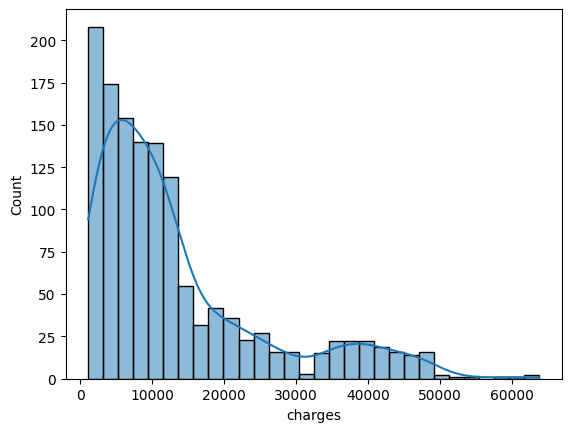

In [ ]:
import seaborn as sns

sns.histplot(df['charges'],kde=True)

In [ ]:
t_tests, p_value = ssw.ztest(df['charges'], value=13270, alternative='two-sided')

In [ ]:
if(p_value<0.05):
  print("We Rejected Null hypothesis")
else:
  print("We Fail to Reject The Null Hypothesis")

We Fail to Reject The Null Hypothesis


Compare medical insurance charges (charges) between male and female customers. Draw an appropriate graph to compare the distributions for both groups. Determine whether the mean insurance charges differ significantly between male and female customers. State the hypotheses using the defender approach, report the test result at \(\alpha = 0.05\), and interpret the findings.

H0:Mean Insurance Charge do not differs between gender

H1:Mean Insurance Charges diifers between gender

Test : Two independent sample t_test



In [ ]:
ct=df['sex'].value_counts()

<Axes: xlabel='sex', ylabel='charges'>

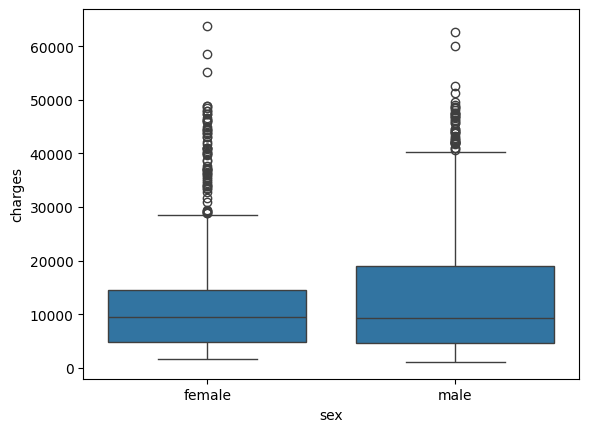

In [ ]:
sns.boxplot(x=df['sex'],y=df['charges'],data=df)

In [ ]:

x=df[df['sex']=='female'].charges
y=df[df['sex']=='male'].charges

In [ ]:

test_stats,p_value,doof=ssw.ttest_ind(x,y,alternative='two-sided')

In [ ]:
if(p_value>0.05):
  print("We Rejected Null hypothesis")
else:
  print("We Fail to Reject The Null Hypothesis")

We Fail to Reject The Null Hypothesis


Conclusion : We dont have enough evidence Reject the Null Hypothesis that the Insurance charge do not differs among Gender

Question 3 – Impact of Smoking Status


Compare insurance charges between smokers and non-smokers. Draw an appropriate graph to compare the two groups. Determine whether smokers have significantly higher mean insurance charges than non-smokers. State the hypotheses using the defender approach, perform the analysis at a 5% significance level, and explain the result in the context of insurance costs.

H0: Mean(Insurance) Charge of smokers is less than mean insurance of charge of non_Smokers

 S_UC<=N_SUC


H1: Mean(Insurance) charge of smoker is higher than mean insurance of charge of non_Smokers


 S_UC > NS_UC

 Test : Two Independent Smaple T test

In [ ]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<Axes: xlabel='smoker', ylabel='charges'>

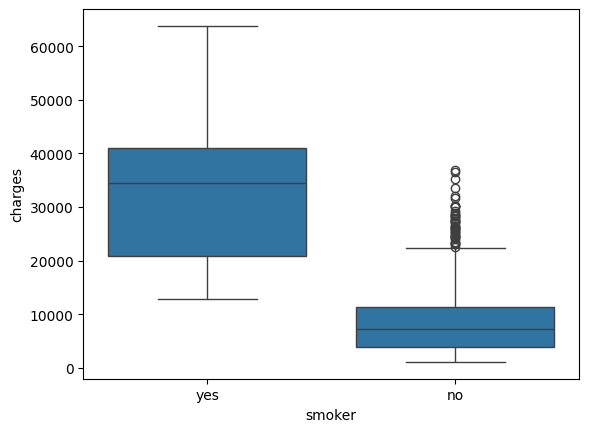

In [ ]:
sns.boxplot(x=df['smoker'],y=df['charges'],data=df)

In [ ]:
smokers=df[df['smoker']=='yes'].charges
non_smokers=df[df['smoker']=='no'].charges

In [ ]:
from statsmodels.stats.api import ttest_ind
t_stat,p_value,ddof=ttest_ind(smokers,non_smokers,alternative='larger')

In [ ]:
if(p_value<0.05):
  print("Rejected Null Hypothesis")
else:
  print("We fail to reject the Null Hypothesis")


Rejected Null Hypothesis


Conclusion: The Mean insurance for the smokers is significantly higher than the mean insurance for the non smokers  

Question 4 – Comparing Insurance Charges Across Regions


Compare medical insurance charges across the four regions (northeast, northwest, southeast, and southwest). Draw an appropriate graph to compare their distributions. Determine whether the population mean insurance charges are equal across all four regions. State the hypotheses, report the test statistic and p-value, and interpret the result.

H0:Insurance charge are Equal Across All four Region  

  UCNW=UCNE=UCSE=UCSW


H1:Insurance charge are not equal across All Four Region  


Atleast one Region mean insurance is different




TEST: ONE WAY ANOVA

<Axes: xlabel='region', ylabel='charges'>

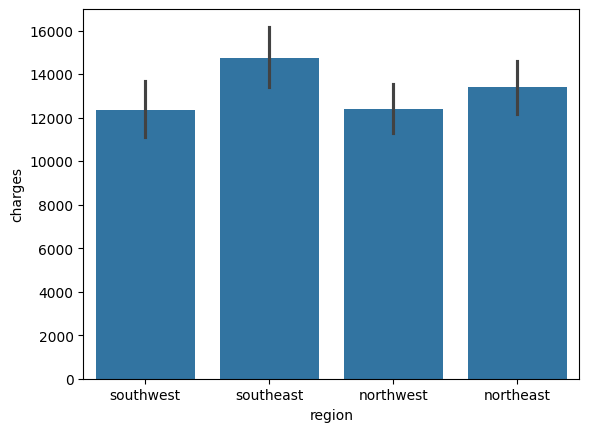

In [ ]:
sns.barplot(y=df['charges'],x=df['region'])

In [ ]:
import statsmodels as sm

In [ ]:
from statsmodels.formula.api import ols
modelss=ols('charges ~ region',data=df).fit()

In [ ]:
anova=sm.stats.api.anova_lm(modelss,typ=2)

In [ ]:
if anova['PR(>F)'].iloc[0] < 0.05:
  print("Reject Null hypothesis")
else:
  print("We Fail To Reject Hypothesis")

Reject Null hypothesis


Conclusion : Insurance charge are not equal across All Four Region

Question 5 – Association Between Gender and Smoking Status



Investigate whether gender (sex) is associated with smoking status (smoker). Create an appropriate visualization to compare the smoking patterns of male and female customers. Determine whether there is a statistically significant association between gender and smoking status. State the hypotheses using the defender approach and interpret the result at \(\alpha = 0.05\)

H0:Gender and smoking Status is not Associated



H1:Gender And Smoking Status are Associated


Type:Chi Square Degree of Association



<Axes: xlabel='region', ylabel='charges'>

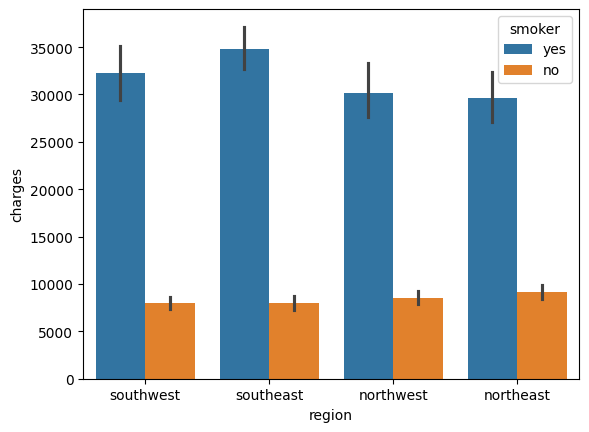

In [ ]:
sns.barplot(x='region', y='charges', hue='smoker', data=df)

In [ ]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
from statsmodels.stats.contingency_tables import Table

data=pd.crosstab(df['sex'],df['smoker'])
table = Table(data)
result = table.test_nominal_association()
p_value=result.pvalue
print("Stats :",result.statistic)
print("P_value : ",p_value)

Stats : 7.76592102860446
P_value :  0.005324114164320548


In [ ]:
if(p_value<0.05):
  print("NULL Hypothesis Rejected")
else:
  print("Fail to reject the Null Hypothesis")

NULL Hypothesis Rejected


Conclusion : We Have Significant Evidence to Conclude that Gender and Smoking Status are Associated  

Compare body mass index (bmi) between male and female customers. Draw an appropriate graph to compare the distributions. Determine whether the mean BMI differs significantly between male and female customers. State the hypotheses, report the test statistic and p-value, and interpret the result.

H0: BMI of Male and Female are Equal

BMI of Male = Bmi of Female

H1:BMI of Male and Female are Not Equal  

BMI if Male != BMI of Female


TEST : Two Sample Independent T test

In [ ]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
bmi_female = df[df['sex'] == 'female']['bmi']
bmi_male = df[df['sex'] == 'male']['bmi']

<Axes: xlabel='sex', ylabel='bmi'>

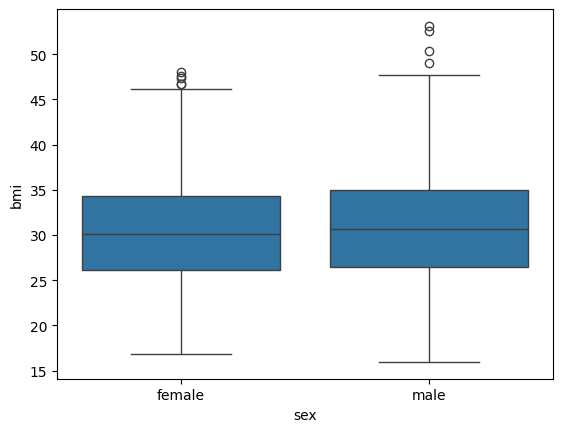

In [ ]:
sns.boxplot(x=df['sex'], y='bmi', data=df)

In [ ]:

test,p_value,ddof=ssw.ttest_ind(bmi_male,bmi_female,alternative='two-sided')


In [ ]:
p_value

np.float64(0.08997637178984932)

In [ ]:
if(p_value<0.05):
  print("Reject the Null Hypothesis")
else:
  print("Fail To Reject Null Hypothesis")

Fail To Reject Null Hypothesis


Conclusion : There are no enough evidence to reject the Null Hypothesis

Question 7 – Relationship Between Age and Insurance Charges



Investigate the relationship between age (age) and medical insurance charges (charges). Create an appropriate visualization to examine the relationship. Determine whether there is a statistically significant linear relationship between age and insurance charges. State the hypotheses, report the relevant statistic and p-value, and interpret your findings.

H0 : There is no significant Linear Realtionship between age and Insurance charge


H1 : there is Significant Linear relationship Between age and Insurance

Test: two sample proprotion t test


<Axes: xlabel='age', ylabel='charges'>

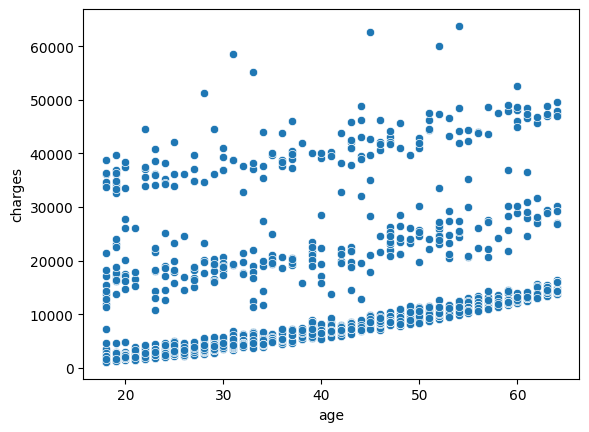

In [ ]:
sns.scatterplot(x=df['age'],y=df['charges'])

In [ ]:
from scipy.stats import pearsonr

In [ ]:
stas,p_value=pearsonr(df['age'],df['charges'])

In [ ]:
p_value

np.float64(4.886693331718529e-29)

In [ ]:
if(p_value<0.05):
  print("Reject Null hyothesis")
else :
  print("Fail to Reject the Null hypothesis")

Reject Null hyothesis


Conclusion : There is Significant Linear Relationship between age and insurance charge

Examine the distribution of customers among the four regions. Create an appropriate graph to display the number of customers in each region. Determine whether customers are equally distributed across the four regions. State the hypotheses, compare the observed and expected frequencies, and interpret the result at a 5% significance level.

H0: Customers are not equally distributed across the four region


H1 : Customers are Equally Distributed across the Four region

Test : Chi Square Godness of fit


In [ ]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<Axes: xlabel='region', ylabel='count'>

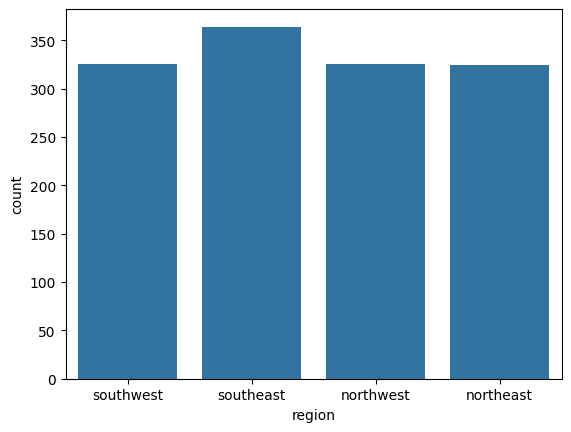

In [ ]:
sns.countplot(x='region', data=df)

In [ ]:
observed_frequencies = df['region'].value_counts()
print(observed_frequencies)

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


In [ ]:
Expected=[sum(observed_frequencies)/len(observed_frequencies)]*len(observed_frequencies)

Expected

[334.5, 334.5, 334.5, 334.5]

In [ ]:
from statsmodels.stats.api import gof


stats,p_value=gof.chisquare(observed_frequencies,Expected)

In [ ]:
p_value

np.float64(0.32456223960286096)

In [ ]:
if(p_value<0.05):
  print("Reject Null hyothesis")
else :
  print("Fail to Reject the Null hypothesis")

Fail to Reject the Null hypothesis


Question 10 – Smoking Status and Region


Investigate whether smoking status (smoker) is associated with region (region). Create an appropriate grouped visualization to compare the proportion of smokers across regions. Determine whether there is a statistically significant association between smoking status and region. State the hypotheses using the defender approach, report the result, and interpret the findings.

H0: Smoking Status is not associated with Region

H1 :Smoking Status is associated with Region

Test : Chi square Degree of Association

In [ ]:
  from statsmodels.stats.contingency_tables import Table
  data=pd.crosstab(df['smoker'],df['region'])

  mod=Table(data)

  result=mod.test_nominal_association()


  p_value=result.pvalue


In [ ]:
p_value

np.float64(0.06171954839170524)

In [ ]:
if(p_value<0.05):
  print("Reject Null hyothesis")
else :
  print("Fail to Reject the Null hypothesis")

Fail to Reject the Null hypothesis
